# IndustryPulseAI — Keşifsel Veri Analizi

Bu notebook, AI4I 2020 veri setinin yapısını, dağılımlarını ve arıza ile ilişkili örüntülerini inceler. Bulgular betimseldir; nedensellik veya model performansı göstermez. Ham veri değiştirilmez.

## 1. Kütüphaneler

Pandas ve NumPy tablo ve sayısal işlemler, Matplotlib ve Seaborn görselleştirme için içe aktarılır. Ortak tema görseller arasında tutarlılık sağlar.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Veri setini yükleme

CSV, proje kökünden veya notebooks klasöründen çalıştırılabilecek bir yol ile okunur. Bu, ham veriyi belleğe alma adımıdır; kaynak dosya değiştirilmez.

In [2]:
root = Path.cwd()
if not (root / "data" / "raw" / "ai4i2020.csv").exists():
    root = root.parent
data_path = root / "data" / "raw" / "ai4i2020.csv"
df = pd.read_csv(data_path)
print(f"Veri kaynağı: {data_path}")

Veri kaynağı: C:\Users\MONSTER\Desktop\IndustryPulseAI\data\raw\ai4i2020.csv


## 3. İlk kayıtlar

İlk on kayıt, değişkenlerin değerlerini ve tablonun genel görünümünü kontrol etmek için gösterilir. Bu işlem örnek gözlem incelemesidir.

In [3]:
display(df.head(10))

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
5,6,M14865,M,298.1,308.6,1425,41.9,11,0,0,0,0,0,0
6,7,L47186,L,298.1,308.6,1558,42.4,14,0,0,0,0,0,0
7,8,L47187,L,298.1,308.6,1527,40.2,16,0,0,0,0,0,0
8,9,M14868,M,298.3,308.7,1667,28.6,18,0,0,0,0,0,0
9,10,M14869,M,298.5,309.0,1741,28.0,21,0,0,0,0,0,0


## 4. Boyut ve sütunlar

Satır ve sütun sayısı ile değişken adları veri setinin kapsamını ve şemasını anlamak için incelenir.

In [4]:
print(f"Satır: {df.shape[0]:,} | Sütun: {df.shape[1]}")
display(pd.DataFrame({"Sütun": df.columns}))

Satır: 10,000 | Sütun: 14


,Sütun
0,UDI
1,Product ID
2,Type
3,Air temperature [K]
4,Process temperature [K]
5,Rotational speed [rpm]
6,Torque [Nm]
7,Tool wear [min]
8,Machine failure
9,TWF


## 5. Veri tipleri

Her sütunun pandas veri tipi gösterilir; bu şema kontrolü sayısal ve kategorik değişkenleri ayırt etmeye yardımcı olur.

In [5]:
display(df.dtypes.rename('Veri tipi').to_frame())

,Veri tipi
UDI,int64
Product ID,str
Type,str
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64
TWF,int64


## 6. Eksik ve tekrarlanan kayıtlar

Sütun bazında eksik değerler ve tüm sütunları aynı olan satırlar sayılır. Bunlar veri kalitesi göstergeleridir; herhangi bir kayıt değiştirilmez.

In [6]:
display(df.isna().sum().rename('Eksik değer').to_frame())
print(f"Toplam eksik değer: {df.isna().sum().sum()}")
print(f"Birebir tekrarlanan satır: {df.duplicated().sum()}")

,Eksik değer
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


Toplam eksik değer: 0
Birebir tekrarlanan satır: 0


## 7. Sayısal özet

Sayısal sütunların sayısı, ortalaması, yayılımı ve yüzdelikleri dağılımları özetler. UDI bir kimlik, ikili sütunlar ise gösterge olduğundan yorumları sensörlerden farklıdır.

In [7]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


## 8. Arıza sınıf dağılımı

Hedefin sınıf sayıları ve oranları sınıf dengesizliğini incelemek için gösterilir. Sınıf dağılımı, örneklerin hedef etiketlerine göre frekansıdır.

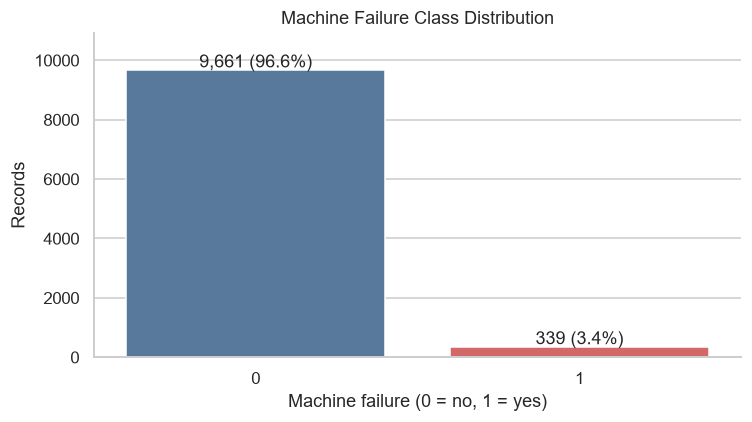

In [8]:
counts = df['Machine failure'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=counts.index.astype(str), y=counts.values, hue=counts.index.astype(str), palette=['#4c78a8', '#e45756'], legend=False, ax=ax)
for i, value in enumerate(counts):
    ax.text(i, value + len(df) * .01, f'{value:,} ({value / len(df):.1%})', ha='center')
ax.set(title='Machine Failure Class Distribution', xlabel='Machine failure (0 = no, 1 = yes)', ylabel='Records', ylim=(0, counts.max() * 1.13))
fig.tight_layout()
plt.show()

## 9. Sensör histogramları

Beş sensörün frekans dağılımları şekil, yayılım ve olası uç değerleri incelemek için histogramlarla gösterilir. Kimlik ve arıza göstergeleri sensör olarak değerlendirilmez.

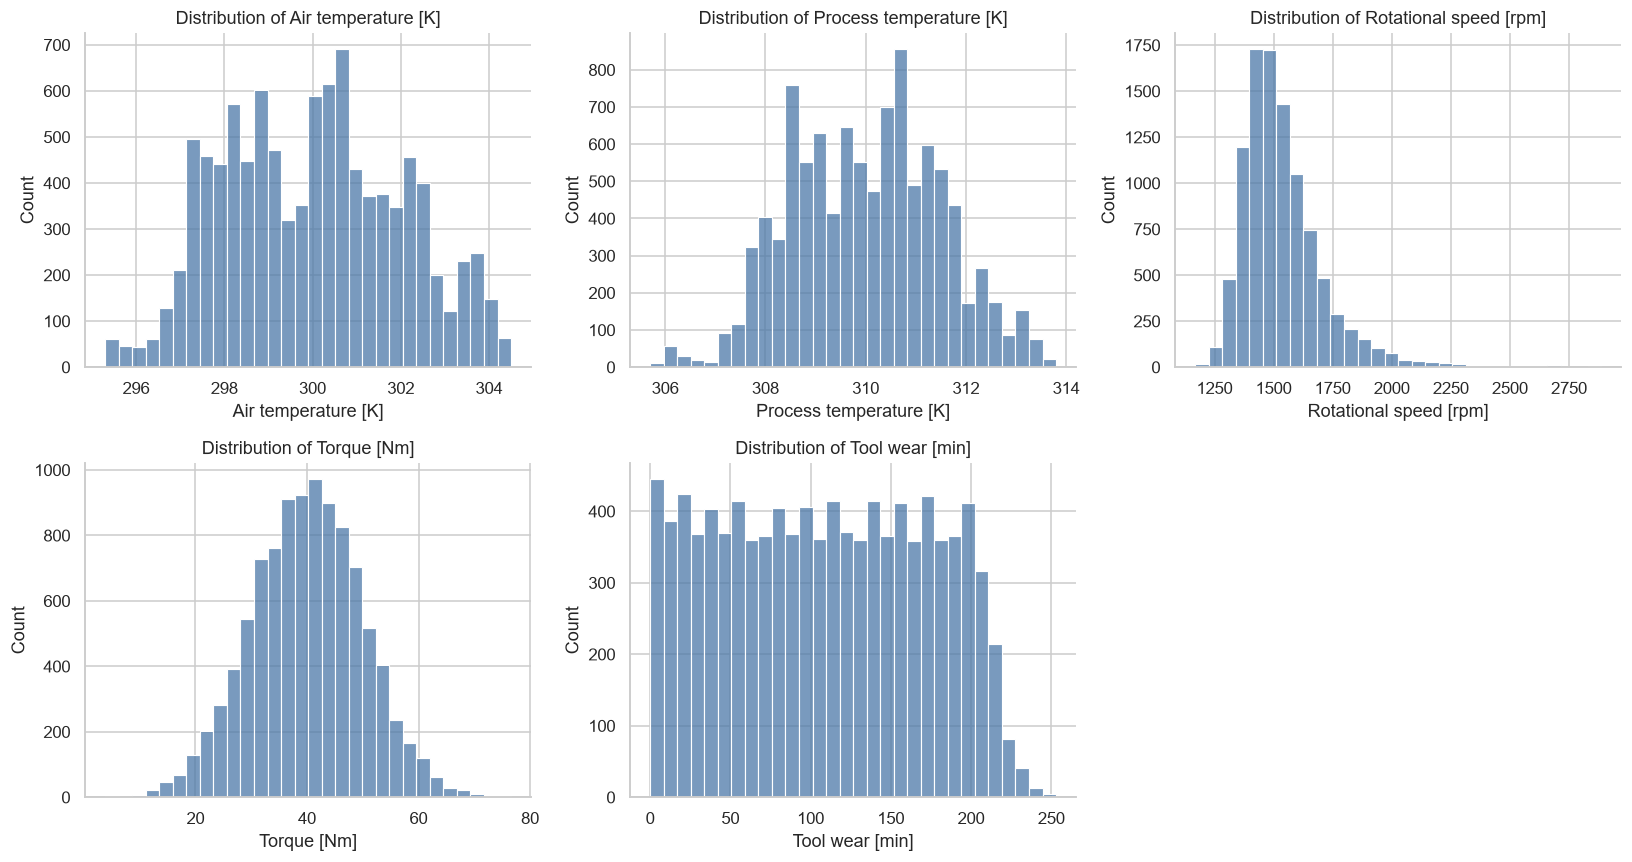

In [9]:
sensors = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.flat, sensors):
    sns.histplot(data=df, x=column, bins=30, color='#4c78a8', ax=ax)
    ax.set_title(f'Distribution of {column}')
axes.flat[-1].set_visible(False)
fig.tight_layout()
plt.show()

## 10. Aykırı değer incelemesi

Kutu grafikleri medyanı, çeyrekleri ve yaygın 1,5 IQR kuralına göre uç noktaları gösterir. İşaretlenen değerler otomatik olarak hatalı kabul edilmez.

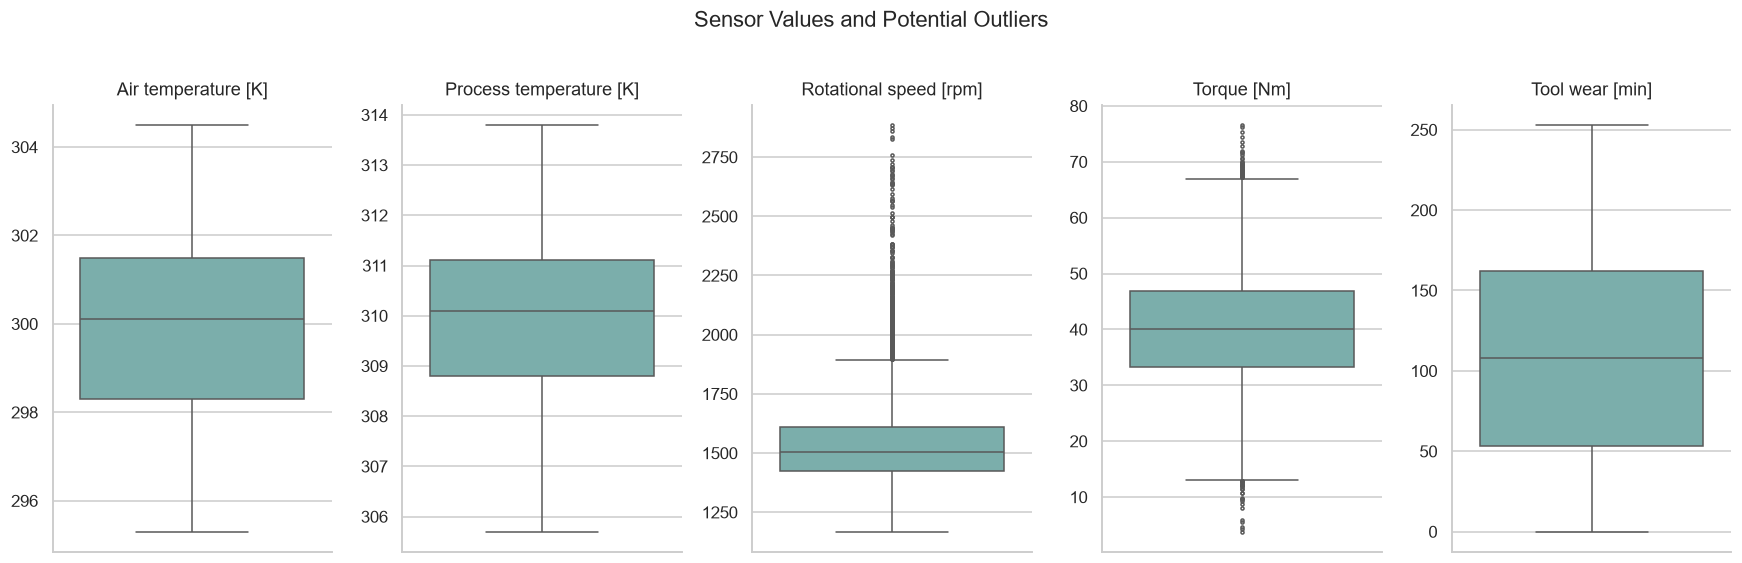

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(16, 5))
for ax, column in zip(axes, sensors):
    sns.boxplot(y=df[column], color='#72b7b2', ax=ax, fliersize=2)
    ax.set(title=column, xlabel='', ylabel='')
fig.suptitle('Sensor Values and Potential Outliers', y=1.02)
fig.tight_layout()
plt.show()

## 11. Korelasyon matrisi

Pearson korelasyonu sayısal değişkenler arasındaki doğrusal ilişkiyi özetler. Kimlik ve arıza modu etiketleri hariç tutulur; korelasyon nedensellik anlamına gelmez.

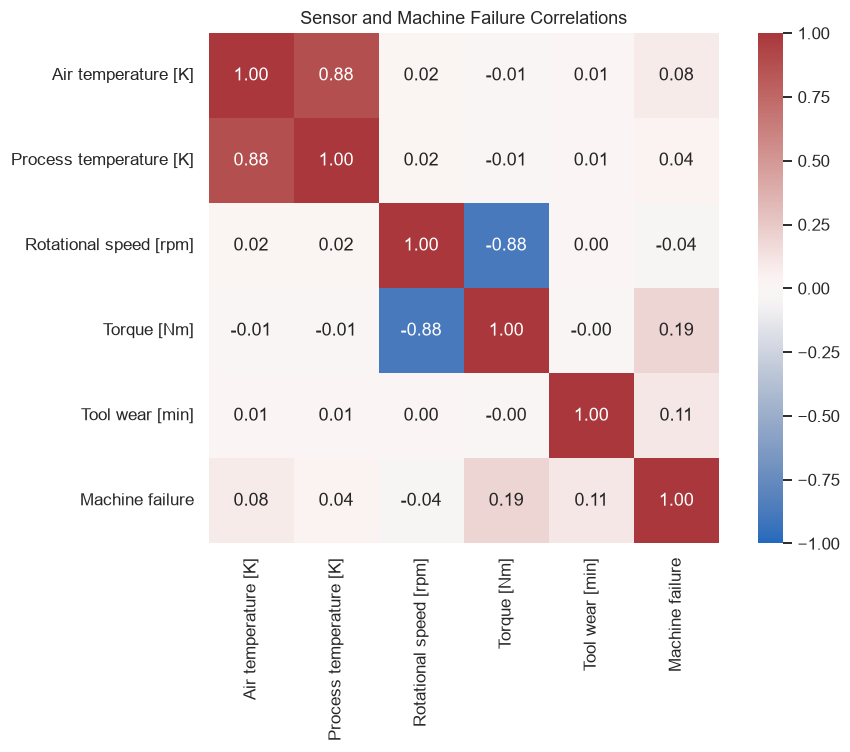

In [11]:
correlation = df[sensors + ['Machine failure']].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title('Sensor and Machine Failure Correlations')
fig.tight_layout()
plt.show()

## 12. Arıza durumuna göre sensörler

Sınıflara göre ortalamalar ve kutu grafikleri sensör dağılımlarını karşılaştırır. Farklar betimseldir ve tek başına nedensel etki göstermez.

Air temperature [K]        Process temperature [K]         \
                               mean median                    mean median   
Machine failure                                                             
0                            299.97  300.0                  310.00  310.0   
1                            300.89  301.6                  310.29  310.4   

                Rotational speed [rpm]         Torque [Nm]         \
                                  mean  median        mean median   
Machine failure                                                     
0                              1540.26  1507.0       39.63   39.9   
1                              1496.49  1365.0       50.17   53.7   

                Tool wear [min]         
                           mean median  
Machine failure                         
0                        106.69  107.0  
1                        143.78  165.0

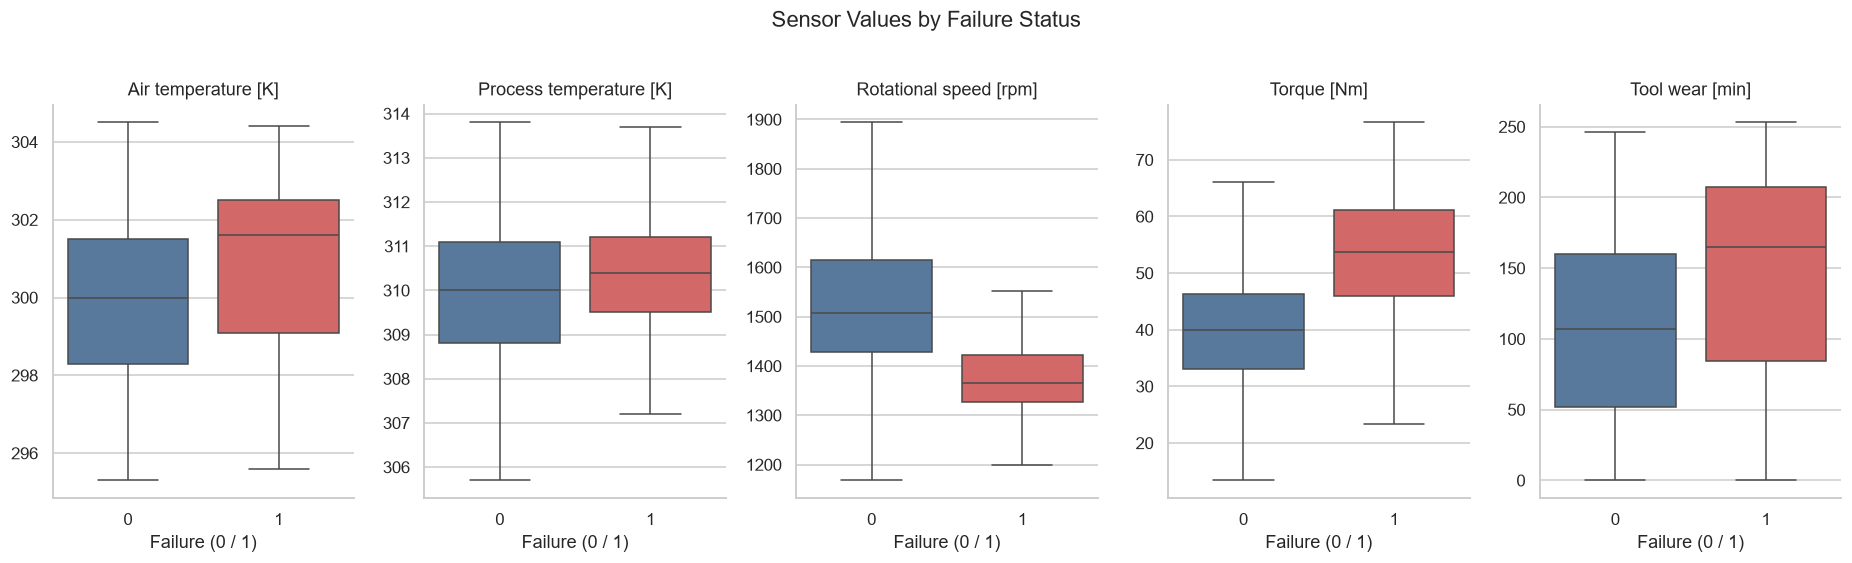

In [12]:
display(df.groupby('Machine failure')[sensors].agg(['mean', 'median']).round(2))
fig, axes = plt.subplots(1, 5, figsize=(17, 5))
for ax, column in zip(axes, sensors):
    sns.boxplot(data=df, x='Machine failure', y=column, hue='Machine failure', palette=['#4c78a8', '#e45756'], legend=False, showfliers=False, ax=ax)
    ax.set(title=column, xlabel='Failure (0 / 1)', ylabel='')
fig.suptitle('Sensor Values by Failure Status', y=1.02)
fig.tight_layout()
plt.show()

## 13. Ürün tipine göre arıza oranı

Her ürün tipi için arıza sayısı, toplam kayıt ve arıza oranı hesaplanır. Oranlar grup büyüklükleri farklı olduğunda karşılaştırmayı kolaylaştırır.

In [13]:
type_summary = df.groupby('Type')['Machine failure'].agg(records='size', failures='sum', failure_rate='mean')
type_summary['failure_rate_pct'] = (type_summary['failure_rate'] * 100).round(2)
display(type_summary)

,records,failures,failure_rate,failure_rate_pct
Type,,,,
H,1003,21,0.020937,2.09
L,6000,235,0.039167,3.92
M,2997,83,0.027694,2.77


## 14. Class Imbalance

Sınıf dengesizliği, hedef sınıfların sayılarının belirgin biçimde farklı olmasıdır. Burada arıza 339/10.000 (%3,39), arızasız durum 9.661/10.000 (%96,61) kayıttır. Her kaydı arızasız tahmin eden bir yaklaşım yaklaşık %96,61 doğruluk elde ederken hiçbir arızayı bulamaz. İleride değerlendirmede yalnızca doğruluğa güvenmek yerine arıza sınıfının precision, recall, F1 ve uygun PR eğrisi gibi ölçütleri dikkate alınmalıdır. Bu notebook yeniden örnekleme veya model eğitimi yapmaz.

## 15. Data Leakage riski

TWF, HDF, PWF, OSF ve RNF gerçekleşmiş arıza türlerine ait göstergelerdir. Bunlar arıza sonucuyla doğrudan ilişkili olduğundan, tahmin anında mevcut değilse özellik olarak kullanılmaları **hedef sızıntısına (data leakage)** yol açabilir: model gerçek kullanımda erişemeyeceği sonuç bilgisini kullanır. İleride bu sütunları girdilerden çıkarmak ve her özelliğin tahmin anında gerçekten mevcut olduğunu doğrulamak gerekir. Bazı etiketlerde tutarsızlık olabileceğinden hedefin bu beş göstergenin kusursuz birleşimi olduğu varsayılmamalıdır.

## 16. Bulguların özeti

- Veri seti 10.000 satır ve 14 sütundan oluşur; eksik hücre ve birebir tekrarlı satır yoktur.
- Arıza oranı %3,39'dur; hedef belirgin biçimde dengesizdir.
- Ürün tipine göre gözlenen arıza oranları H için %2,09 (21/1.003), L için %3,92 (235/6.000), M için %2,77'dir (83/2.997).
- Arızalı kayıtlarda ortalama tork yaklaşık 50,17 Nm, arızasız kayıtlarda 39,63 Nm; ortalama takım aşınması sırasıyla 143,78 ve 106,69 dakikadır. Bunlar betimsel ilişkilerdir.
- Kutu grafiklerindeki uç değerler araştırma gerektirir; bu aşamada veri temizliği yapılmamıştır.
- Arıza türü sütunları hedef sızıntısı açısından ayrıca ele alınmalıdır. Ham veri değiştirilmemiştir.